# TSLA 15m: очистка, визуализация и признаки

Учебный ноутбук по итогам трёх занятий:
- **Урок 6** — очистка данных: дубликаты, пропуски, неинформативные признаки, выбросы;
- **Урок 5** — визуализация: шесть графиков для разведочного анализа;
- **Урок 2** — создание признаков: места с `# TODO`, которые нужно сделать самой.

**Данные:** `tsla_15m_dataset_3y_daily.csv` — 15-минутные свечи TSLA за 3 года (сен 2023 – окт 2026),
66 признаков, целевые переменные `target_ret` (доходность следующей свечи) и `target_up` (выросла ли).

Положите CSV в одну папку с ноутбуком и запускайте ячейки сверху вниз.

> **Главная мысль ноутбука.** Методы из уроков придуманы для «обычных» таблиц (квартиры, пациенты),
> где строки независимы друг от друга. Биржевые данные — это **временной ряд**: порядок строк важен,
> и будущее нельзя использовать для обработки прошлого. Поэтому часть приёмов работает как в уроке,
> часть — с оговорками, а часть применять нельзя. Каждый раздел заканчивается блоком
> **«Можно / нельзя для биржевых данных»**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)

# Единая палитра для всех графиков (порядок цветов фиксирован)
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
SPLIT_COLORS = {'train': BLUE, 'val': ORANGE, 'test': AQUA}

plt.rcParams.update({
    'figure.figsize': (12, 4.5), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
})

DATA_PATH = 'tsla_15m_dataset_3y_daily.csv'
df = pd.read_csv(DATA_PATH, parse_dates=['datetime'])
df['date'] = pd.to_datetime(df['date'])
print(df.shape)
df.head()

(19391, 76)


,datetime,date,split,open,high,low,close,volume,rsi,rsi_ma,gap_open,prev_day_ret,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_8,ret_4,ret_26,ret_from_open,range_pct,body_pct,upper_wick,lower_wick,bb_pos,bb_width,dist_sma50,volatility_20,atr_pct,rsi_minus_ma,macd_norm,macd_hist_norm,bar_of_day,dow,rel_volume,volume_z,day_volume_rel,obv_slope_20,dist_vwap,nvda_ret_1,nvda_ret_4,nvda_ret_from_open,spy_ret_1,spy_ret_4,spy_ret_from_open,qqq_ret_1,qqq_ret_4,qqq_ret_from_open,xly_ret_1,xly_ret_4,xly_ret_from_open,beta_qqq,corr_qqq_26,resid_qqq_4,resid_qqq_day,rel_nvda_4,d_dist_sma20,d_dist_sma50,d_dist_sma200,d_ret_5,d_ret_20,d_vol_20,d_vol_ratio,d_rsi,d_volume_rel,d_vix,d_vix_chg_1,d_vix_chg_5,d_vix_z20,d_dxy_chg_1,d_dxy_chg_5,d_us10y,d_us10y_chg_1,d_us10y_chg_5,target_ret,target_up
0,2023-09-11 09:30:00,2023-09-11,train,264.08,264.88,260.62,262.31,2005612,77.840522,41.899696,0.06291,-0.012049,0.055786,0.002421,-0.002094,0.000846,-0.000525,0.057020,0.025209,-0.006703,0.016240,-0.006703,0.003050,0.006443,1.693185,0.058163,0.048004,0.013085,0.008934,35.940826,0.000920,0.003352,0,0,1.417847,5.482618,1.417847,0.077429,-0.001117,-0.015824,-0.016363,0.000000,0.004826,0.006045,0.000000,0.005503,0.006746,0.000000,0.016057,0.017504,0.000000,2.259226,0.778131,0.041780,-0.006703,0.073383,0.033258,-0.030543,0.242961,-0.03712,0.01288,0.034164,1.101394,50.809863,1.024497,13.83,-0.039583,0.019912,-1.059936,0.000295,0.014196,4.268,0.02,0.158,0.007701,1
1,2023-09-11 09:45:00,2023-09-11,train,262.36,265.94,261.14,264.33,1641774,79.751824,44.571334,0.06291,-0.012049,0.007701,0.055786,0.002421,-0.002094,0.003842,0.064259,0.041736,0.000947,0.018159,0.007509,0.006091,0.004615,1.439561,0.076540,0.054456,0.013141,0.009823,35.180490,0.004980,0.005914,1,0,1.796659,3.541090,1.566518,0.184982,0.004509,-0.005753,-0.018167,-0.005753,-0.001541,0.005127,-0.001541,-0.000828,0.006670,-0.000828,0.000233,0.017621,0.000233,2.250461,0.751949,0.049248,0.002809,0.082426,0.033258,-0.030543,0.242961,-0.03712,0.01288,0.034164,1.101394,50.809863,1.024497,13.83,-0.039583,0.019912,-1.059936,0.000295,0.014196,4.268,0.02,0.158,-0.002648,0
2,2023-09-11 10:00:00,2023-09-11,train,264.37,265.90,262.93,263.63,897417,77.264784,47.542266,0.06291,-0.012049,-0.002648,0.007701,0.055786,0.002421,-0.002498,0.063668,0.038895,-0.001704,0.011266,-0.002799,0.005804,0.002655,1.127989,0.089040,0.050206,0.013175,0.009911,29.722518,0.007919,0.007085,2,0,1.106897,1.241676,1.447809,0.132363,0.001090,-0.004329,-0.022859,-0.010057,-0.000157,0.004157,-0.001698,-0.001149,0.005108,-0.001975,-0.000286,0.017089,-0.000052,2.257813,0.780350,0.052134,0.002756,0.086526,0.033258,-0.030543,0.242961,-0.03712,0.01288,0.034164,1.101394,50.809863,1.024497,13.83,-0.039583,0.019912,-1.059936,0.000295,0.014196,4.268,0.02,0.158,0.002655,1
3,2023-09-11 10:15:00,2023-09-11,train,263.66,264.73,262.63,264.33,669244,78.003505,50.661319,0.06291,-0.012049,0.002655,-0.002648,0.007701,0.055786,0.002262,0.063916,0.037402,0.000947,0.007945,0.002541,0.001513,0.003897,1.007454,0.100543,0.051399,0.013131,0.009901,27.342186,0.010305,0.007579,3,0,1.167082,0.541864,1.404448,0.212705,0.003478,0.005339,-0.020520,-0.004772,0.002036,0.005163,0.000335,0.002113,0.005637,0.000133,0.002385,0.018427,0.002333,2.247790,0.761019,0.051246,0.000647,0.084436,0.033258,-0.030543,0.242961,-0.03712,0.01288,0.034164,1.101394,50.809863,1.024497,13.83,-0.039583,0.019912,-1.059936,0.000295,0.014196,4.268,0.02,0.158,0.003329,1
4,2023-09-11 10:30:00,2023-09-11,train,264.33,266.12,263.21,265.21,771834,78.930352,53.640055,0.06291,-0.012049,0.003329,0.002655,-0.002648,0.007701,0.000846,0.011056,0.043887,0.004279,0.010972,0.003329,0.003431,0.004223,0.924361,0.111339,0.053302,0.013079,0.010334,25.290297,0.012299,0.007665,4,0,1.415539,0.820235,1.405868,0.302657,0.006113,0.004705,-0.000089,-0.000089,-0.001195,-0.000860,-0.000860,-0.000667,-0.000534,-0.000534,-0.000291,0.002041,0.002041,2.232944,0.762041,0.012248,0.005471,0.011145,0.033258,-0.030543,0.242961,-0.03712,0

In [2]:
# Какие столбцы есть и каких они типов
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19391 entries, 0 to 19390
Data columns (total 76 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   datetime            19391 non-null  datetime64[us]
 1   date                19391 non-null  datetime64[us]
 2   split               19391 non-null  str           
 3   open                19391 non-null  float64       
 4   high                19391 non-null  float64       
 5   low                 19391 non-null  float64       
 6   close               19391 non-null  float64       
 7   volume              19391 non-null  int64         
 8   rsi                 19391 non-null  float64       
 9   rsi_ma              19391 non-null  float64       
 10  gap_open            19391 non-null  float64       
 11  prev_day_ret        19391 non-null  float64       
 12  ret_lag_1           19391 non-null  float64       
 13  ret_lag_2           19391 non-null  float64       
 14  r

Столбцы делятся на группы:

| Группа | Столбцы |
|---|---|
| служебные | `datetime`, `date`, `split` (train / val / test) |
| сырые цены и объём | `open`, `high`, `low`, `close`, `volume` |
| **признаки** | всё остальное, кроме целевых |
| **целевые** | `target_ret`, `target_up` |

In [3]:
SERVICE = ['datetime', 'date', 'split']
RAW = ['open', 'high', 'low', 'close', 'volume']
TARGETS = ['target_ret', 'target_up']
FEATURES = [c for c in df.columns if c not in SERVICE + RAW + TARGETS]
print('Признаков:', len(FEATURES))
print(FEATURES)

Признаков: 66
['rsi', 'rsi_ma', 'gap_open', 'prev_day_ret', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_4', 'ret_lag_8', 'ret_4', 'ret_26', 'ret_from_open', 'range_pct', 'body_pct', 'upper_wick', 'lower_wick', 'bb_pos', 'bb_width', 'dist_sma50', 'volatility_20', 'atr_pct', 'rsi_minus_ma', 'macd_norm', 'macd_hist_norm', 'bar_of_day', 'dow', 'rel_volume', 'volume_z', 'day_volume_rel', 'obv_slope_20', 'dist_vwap', 'nvda_ret_1', 'nvda_ret_4', 'nvda_ret_from_open', 'spy_ret_1', 'spy_ret_4', 'spy_ret_from_open', 'qqq_ret_1', 'qqq_ret_4', 'qqq_ret_from_open', 'xly_ret_1', 'xly_ret_4', 'xly_ret_from_open', 'beta_qqq', 'corr_qqq_26', 'resid_qqq_4', 'resid_qqq_day', 'rel_nvda_4', 'd_dist_sma20', 'd_dist_sma50', 'd_dist_sma200', 'd_ret_5', 'd_ret_20', 'd_vol_20', 'd_vol_ratio', 'd_rsi', 'd_volume_rel', 'd_vix', 'd_vix_chg_1', 'd_vix_chg_5', 'd_vix_z20', 'd_dxy_chg_1', 'd_dxy_chg_5', 'd_us10y', 'd_us10y_chg_1', 'd_us10y_chg_5']


---
# Часть A. Очистка данных (урок 6)
## A1. Дубликаты

In [4]:
full_dups = df.duplicated().sum()
time_dups = df['datetime'].duplicated().sum()
print('Полных дубликатов строк:', full_dups)
print('Повторяющихся моментов времени:', time_dups)

Полных дубликатов строк: 0
Повторяющихся моментов времени: 0


**Можно / нельзя для биржевых данных**

✅ **Можно, и это обязательно.** Для временного ряда важнее второй вид проверки — по `datetime`:
две свечи с одним и тем же временем означают ошибку выгрузки или склейки файлов.
Если дубли по времени найдутся, оставляют одну строку (`drop_duplicates('datetime')`).

## A2. Пропуски

### Явные пропуски

In [5]:
missing = df.isnull().mean().mul(100).round(2)
print('Столбцов с пропусками:', (missing > 0).sum())
missing[missing > 0]

Столбцов с пропусками: 0


Series([], dtype: float64)

В готовом датасете пропусков нет: они уже обработаны при сборке. Посмотрим, какими они были
**в исходной выгрузке TradingView** — так же, как в уроке строили столбчатую диаграмму пропусков.

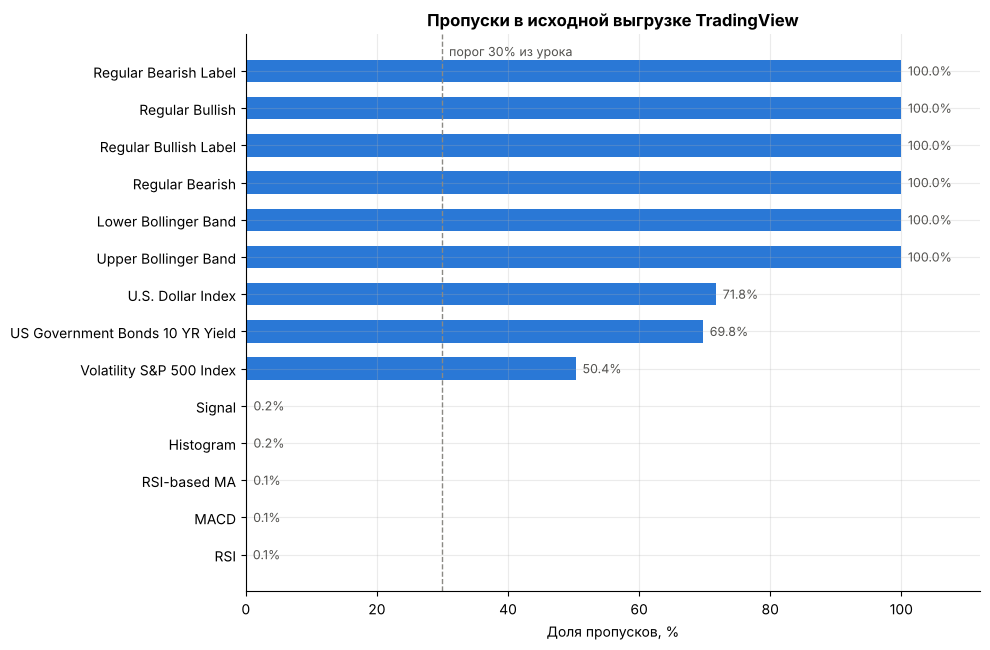

In [6]:
import os

RAW_PATH = 'BATS_TSLA 15_4.csv'   # исходная выгрузка; если файла нет — ячейка просто пропустится

if os.path.exists(RAW_PATH):
    raw = pd.read_csv(RAW_PATH)
    raw_missing = raw.isnull().mean().mul(100).sort_values()
    raw_missing = raw_missing[raw_missing > 0]
    short = [c.split(' · ')[0][:38] for c in raw_missing.index]

    fig, ax = plt.subplots(figsize=(10, 0.4 * len(raw_missing) + 1))
    ax.barh(short, raw_missing.values, color=BLUE, height=0.6)
    for y, v in enumerate(raw_missing.values):
        ax.text(v + 1, y, f'{v:.1f}%', va='center', fontsize=9, color='#52514e')
    ax.axvline(30, color=GRAY, ls='--', lw=1)
    ax.text(31, len(raw_missing) - 0.6, 'порог 30% из урока', fontsize=9, color='#52514e')
    ax.set_xlim(0, 112)
    ax.set_xlabel('Доля пропусков, %')
    ax.set_title('Пропуски в исходной выгрузке TradingView')
    plt.tight_layout(); plt.show()
else:
    print(f'Файл {RAW_PATH} не найден — положите исходную выгрузку рядом, чтобы увидеть график.')

Что было сделано с этими пропусками при сборке датасета:

| Столбец | Пропуски | Что сделано | Метод из урока |
|---|---|---|---|
| Bollinger, дивергенции | 100% | удалены | удаление признака (> 30–40%) |
| VIX, DXY, US10Y (15 мин) | 50–72% | удалены, заменены дневными данными | удаление признака + **внешний источник** |
| RSI, MACD в первых строках | < 1% | строки удалены | удаление записей |
| редкие пропуски QQQ, NVDA и др. | доли % | заполнены **предыдущим** значением (не дальше часа) | заполнение константой — но другой |

### Скрытые пропуски

В уроке с диабетом пропуски прятались как нули. Проверим, есть ли такое у нас.

In [7]:
hidden = {
    'нулевой объём': (df['volume'] == 0).sum(),
    'свеча без движения (high == low)': (df['high'] == df['low']).sum(),
    'цена <= 0': (df[['open', 'high', 'low', 'close']] <= 0).any(axis=1).sum(),
}
pd.Series(hidden, name='строк')

нулевой объём                       0
свеча без движения (high == low)    0
цена <= 0                           0
Name: строк, dtype: int64

**Можно / нельзя для биржевых данных**

✅ **Можно:** удалять признаки, где пропусков больше 30–40%; удалять первые строки, где индикаторам
не хватило истории; искать скрытые пропуски.

❌ **Нельзя: заполнять пропуски медианой или средним по всему столбцу.** Медиана считается по всем
трём годам, включая будущее. Если подставить её в строку 2023 года, модель получит информацию
из 2026 года. Это называется **утечка данных (data leakage)**: на истории модель выглядит отлично,
а в реальной торговле не работает.

✅ **Правильно для временных рядов:** заполнять **прошлым** значением (`ffill`) — так поступил бы
трейдер, который видит только то, что уже произошло. Если медиана всё же нужна, считать её только по train.

## A3. Неинформативные признаки

Функция из урока: признак неинформативен, если одно значение занимает ≥ 95% строк
**или** ≥ 95% значений уникальны.

In [8]:
def low_information_features(data, columns, threshold=0.95):
    result = []
    for col in columns:
        top_freq = data[col].value_counts(normalize=True).iloc[0]   # доля самого частого значения
        nunique_ratio = data[col].nunique() / data[col].count()     # доля уникальных значений
        if top_freq >= threshold:
            result.append((col, 'одно значение', round(top_freq, 3)))
        elif nunique_ratio >= threshold:
            result.append((col, 'все уникальные', round(nunique_ratio, 3)))
    return pd.DataFrame(result, columns=['признак', 'причина', 'доля'])

low_info = low_information_features(df, FEATURES)
print(f'Помечено {len(low_info)} из {len(FEATURES)} признаков')
low_info['причина'].value_counts()

Помечено 40 из 66 признаков


причина
все уникальные    40
Name: count, dtype: int64

**Можно / нельзя для биржевых данных**

✅ **Правило «одно значение в 95% строк» — можно.** Такой признак почти не меняется и модели бесполезен.
У нас таких нет.

❌ **Правило «95% уникальных» — нельзя для непрерывных чисел.** Оно придумано для идентификаторов
(номер клиента, id квартиры): уникальный номер ничего не говорит о цене. Но у доходностей, цен и
индикаторов каждое значение уникально по природе — `0.00213` и `0.00214` это разные числа.
Если удалить всё, что пометила функция, от датасета почти ничего не останется.

Применяем только первое правило:

In [9]:
truly_constant = low_info[low_info['причина'] == 'одно значение']
print('Действительно неинформативных признаков:', len(truly_constant))
truly_constant

Действительно неинформативных признаков: 0


,признак,причина,доля


### Почти одинаковые признаки (мультиколлинеарность)

Ещё один вид «лишних» признаков — пары, которые почти повторяют друг друга.

In [10]:
corr = df[FEATURES].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
pairs = pairs[pairs > 0.85].round(3).rename('|корреляция|')
pairs.to_frame()

|корреляция|
dist_sma50        macd_norm                 0.963
spy_ret_from_open qqq_ret_from_open         0.954
spy_ret_4         qqq_ret_4                 0.945
spy_ret_1         qqq_ret_1                 0.945
d_dist_sma20      d_rsi                     0.935
ret_26            macd_norm                 0.929
                  dist_sma50                0.926
d_dist_sma50      d_rsi                     0.902
rsi_ma            macd_norm                 0.894
rsi               dist_sma50                0.881
d_dist_sma50      d_ret_20                  0.871
spy_ret_from_open xly_ret_from_open         0.861
rsi               bb_pos                    0.856
d_ret_20          d_rsi                     0.856
ret_from_open     resid_qqq_day             0.851

**Можно / нельзя:** ✅ для **линейных моделей** (логистическая регрессия) из каждой пары лучше
оставить один признак — например, только QQQ из пары SPY/QQQ. Градиентный бустинг к таким парам
устойчив, для него удалять не обязательно.

In [11]:
# TODO: впишите сюда признаки, которые вы уберёте для линейной модели (по одному из каждой пары выше).
# Пример: DROP_FOR_LINEAR = ['spy_ret_1', 'spy_ret_4', 'spy_ret_from_open']
DROP_FOR_LINEAR = []

print('Будет убрано для линейной модели:', DROP_FOR_LINEAR or 'пока ничего — заполните список')

Будет убрано для линейной модели: пока ничего — заполните список


## A4. Выбросы

Функции из урока: метод Тьюки (IQR) и метод трёх сигм (z-отклонения).

In [12]:
def outliers_iqr(data, feature, left=1.5, right=1.5):
    x = data[feature]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - left * iqr, q3 + right * iqr
    outliers = data[(x < lower) | (x > upper)]
    cleaned = data[(x >= lower) & (x <= upper)]
    return outliers, cleaned


def outliers_z_score(data, feature, left=3, right=3, log_scale=False):
    x = np.log(data[feature] + 1) if log_scale else data[feature]
    mu, sigma = x.mean(), x.std()
    lower, upper = mu - left * sigma, mu + right * sigma
    outliers = data[(x < lower) | (x > upper)]
    cleaned = data[(x >= lower) & (x <= upper)]
    return outliers, cleaned


rows = []
for f in ['ret_lag_1', 'target_ret', 'range_pct', 'volume', 'rel_volume']:
    o_iqr, _ = outliers_iqr(df, f)
    o_z, _ = outliers_z_score(df, f)
    rows.append({'признак': f,
                 'выбросы IQR': len(o_iqr), 'IQR, %': round(len(o_iqr) / len(df) * 100, 1),
                 'выбросы 3σ': len(o_z),
                 'эксцесс': round(df[f].kurt(), 1)})
pd.DataFrame(rows)

,признак,выбросы IQR,"IQR, %",выбросы 3σ,эксцесс
0,ret_lag_1,1347,6.9,305,64.6
1,target_ret,1028,5.3,271,10.6
2,range_pct,1213,6.3,356,26.9
3,volume,1314,6.8,380,19.0
4,rel_volume,987,5.1,329,18.9


Эксцесс (kurtosis) у нормального распределения равен 0. У доходностей TSLA он в десятки раз больше:
крупные движения случаются намного чаще, чем предсказывает нормальное распределение.
Это называется **«толстые хвосты»**, и это природа рынка.

Посмотрим, что это за «выбросы» на самом деле:

In [13]:
o_iqr, _ = outliers_iqr(df, 'ret_lag_1')
(o_iqr.assign(abs_ret=o_iqr['ret_lag_1'].abs())
      .sort_values('abs_ret', ascending=False)
      [['datetime', 'close', 'ret_lag_1', 'rel_volume', 'gap_open']]
      .head(10))

,datetime,close,ret_lag_1,rel_volume,gap_open
7051,2024-10-24 09:30:00,249.17,0.166690,4.600987,0.145667
7276,2024-11-06 09:30:00,286.93,0.141056,2.543911,0.132307
3963,2024-04-29 09:30:00,187.40,0.113686,2.112875,0.119689
3888,2024-04-24 09:30:00,160.44,0.107935,1.941136,0.125337
5426,2024-07-24 09:30:00,220.14,-0.106502,1.475114,-0.085924
17866,2026-07-23 09:30:00,334.33,-0.106476,3.331837,-0.088569
9802,2025-04-07 09:30:00,216.10,-0.097063,1.193084,-0.064931
2338,2024-01-25 09:30:00,188.81,-0.091211,3.022625,-0.087120
11640,2025-07-24 09:30:00,305.00,-0.083836,3.130470,-0.068547
6826,2024-10-11 09:30:00,218.82,-0.083476,3.667149,-0.077990


Почти все крупнейшие «выбросы» — это **первая свеча дня** (большой `gap_open`) с огромным объёмом:
реакция на квартальные отчёты, поставки и новости, вышедшие ночью. Это реальные события,
а не ошибки ввода.

**Можно / нельзя для биржевых данных**

❌ **Нельзя удалять строки-выбросы.**
1. Это реальные движения — именно на них зарабатывают и теряют деньги. Модель, которая их не видела,
   окажется не готова к ним в реальности.
2. Удаление строк ломает временной ряд: лаги (`ret_lag_2`, `ret_lag_3`…) начнут ссылаться на свечи,
   которые на самом деле не были предыдущими.
3. **Целевую переменную в test трогать нельзя никогда** — иначе оценка модели будет нечестной
   (модель «проверят» на облегчённых данных).

✅ **Можно: ограничить крайние значения признаков (winsorization / clipping).** Строка остаётся,
но слишком большое значение «подрезается» до границы. Это помогает линейным моделям; деревьям
не нужно. **Границы считаются только по train** — по той же причине, что и с медианой.

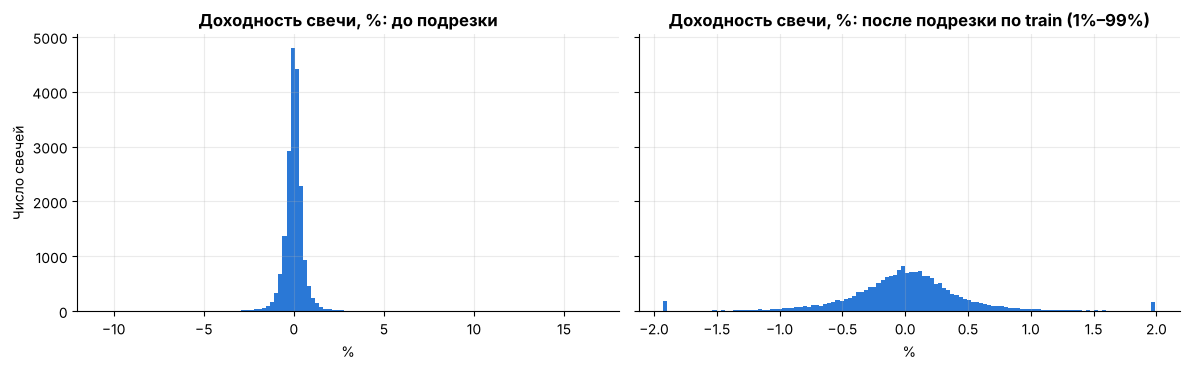

In [14]:
def clip_by_train(data, features, lower_q=0.01, upper_q=0.99):
    # Подрезает признаки по перцентилям, посчитанным ТОЛЬКО на train
    train = data[data['split'] == 'train']
    bounds = train[features].quantile([lower_q, upper_q])
    clipped = data.copy()
    for f in features:
        clipped[f] = clipped[f].clip(bounds.loc[lower_q, f], bounds.loc[upper_q, f])
    return clipped, bounds

df_clipped, clip_bounds = clip_by_train(df, ['ret_lag_1', 'rel_volume'])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, data, title in [(axes[0], df, 'до подрезки'), (axes[1], df_clipped, 'после подрезки по train (1%–99%)')]:
    ax.hist(data['ret_lag_1'] * 100, bins=120, color=BLUE)
    ax.set_title(f'Доходность свечи, %: {title}')
    ax.set_xlabel('%')
axes[0].set_ylabel('Число свечей')
plt.tight_layout(); plt.show()

Слева видно, что редкие экстремальные свечи (до −10% и +16%) растягивают ось, и основная масса
сжимается в узкий пик. Справа значения за пределами 1-го и 99-го перцентиля train «подрезаны» до границ,
поэтому у краёв появились столбики: это те самые подрезанные свечи. Строки при этом не удалены.

---
# Часть B. Визуализация (урок 5)

Шесть графиков, каждый отвечает на конкретный вопрос о данных. Под каждым — место для вашего вывода,
как в уроке («**Выводы по графику:**»).

## B1. Линейный график: цена за 3 года и разбиение на train / val / test

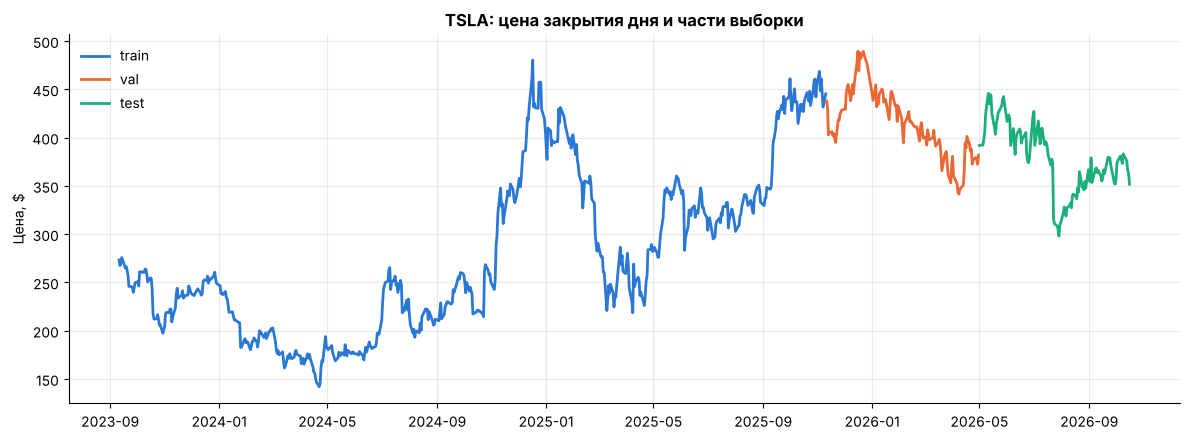

In [15]:
daily_close = df.groupby(['date', 'split'], as_index=False)['close'].last()

fig, ax = plt.subplots()
for split, color in SPLIT_COLORS.items():
    part = daily_close[daily_close['split'] == split]
    ax.plot(part['date'], part['close'], color=color, lw=2, label=split)
ax.set_title('TSLA: цена закрытия дня и части выборки')
ax.set_ylabel('Цена, $')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

**Выводы по графику:** _впишите сами._ Подсказка: в каких рыночных режимах (рост, падение, боковик)
оказалась каждая часть? Похожи ли условия в train и test? Если test — сплошной рост, а train — падение,
модели будет трудно.

## B2. Гистограмма: распределение доходности свечи

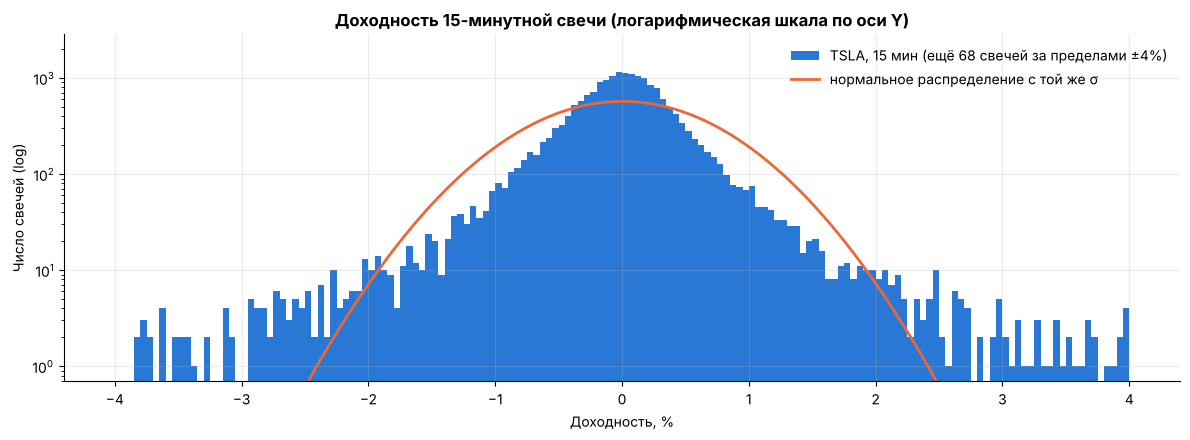

In [16]:
from scipy import stats

r = df['ret_lag_1'] * 100
LIM = 4
bins = np.linspace(-LIM, LIM, 161)
outside = (r.abs() > LIM).sum()

fig, ax = plt.subplots()
ax.hist(r[r.abs() <= LIM], bins=bins, color=BLUE, label=f'TSLA, 15 мин (ещё {outside} свечей за пределами ±{LIM}%)')
x = np.linspace(-LIM, LIM, 400)
normal = stats.norm.pdf(x, r.mean(), r.std()) * len(r) * (bins[1] - bins[0])
ax.plot(x, normal, color=ORANGE, lw=2, label='нормальное распределение с той же σ')
ax.set_yscale('log')
ax.set_ylim(bottom=0.7)
ax.set_title('Доходность 15-минутной свечи (логарифмическая шкала по оси Y)')
ax.set_xlabel('Доходность, %')
ax.set_ylabel('Число свечей (log)')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Выводы по графику:** _впишите сами._ Подсказка: где синяя гистограмма выше оранжевой кривой?
Что это говорит о частоте крупных движений и о том, стоит ли считать их выбросами?

## B3. Boxplot: волатильность в течение торгового дня

Волатильность измеряем размахом свечи — насколько цена прошла от минимума до максимума за 15 минут.

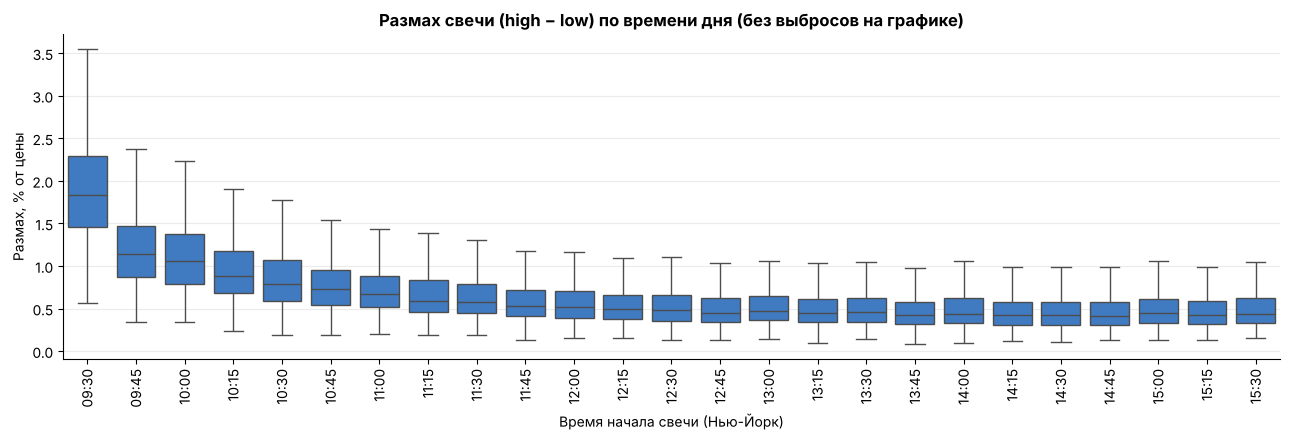

In [17]:
# Размах свечи (high - low) / close: движение ВНУТРИ 15 минут.
# Доходность close/close здесь не подходит: у первой свечи дня в неё попадает ночной гэп.
tmp = df.assign(range_p=df['range_pct'] * 100,
                time=df['datetime'].dt.strftime('%H:%M'))
order = sorted(tmp['time'].unique())

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(data=tmp, x='time', y='range_p', order=order, color=BLUE,
            showfliers=False, linewidth=1, ax=ax)
ax.set_title('Размах свечи (high − low) по времени дня (без выбросов на графике)')
ax.set_xlabel('Время начала свечи (Нью-Йорк)')
ax.set_ylabel('Размах, % от цены')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

**Выводы по графику:** _впишите сами._ Подсказка: в какое время дня рынок самый «шумный»?
Как это связано с признаком `bar_of_day` и почему он может быть полезен модели?

## B4. Столбчатая диаграмма: баланс классов `target_up`

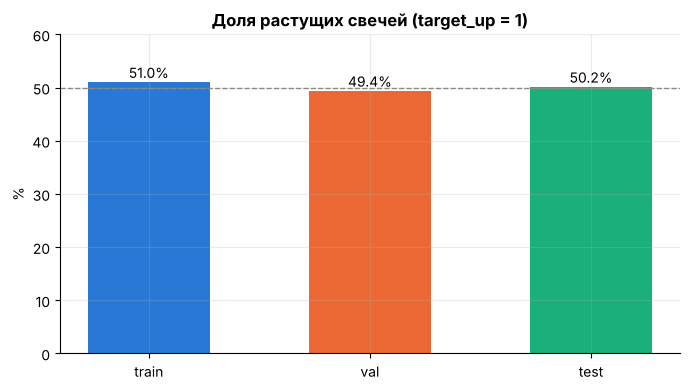

In [18]:
balance = df.groupby('split')['target_up'].mean().reindex(['train', 'val', 'test']) * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(balance.index, balance.values, color=[SPLIT_COLORS[s] for s in balance.index], width=0.55)
ax.axhline(50, color=GRAY, ls='--', lw=1)
for b, v in zip(bars, balance.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center', fontsize=10)
ax.set_ylim(0, 60)
ax.set_title('Доля растущих свечей (target_up = 1)')
ax.set_ylabel('%')
plt.tight_layout(); plt.show()

**Выводы по графику:** _впишите сами._ Подсказка: сбалансированы ли классы? Какую точность (accuracy)
даст «глупая» модель, которая всегда отвечает «вырастет»? С этим числом мы будем сравнивать настоящие модели.

## B5. Тепловая карта: корреляции признаков

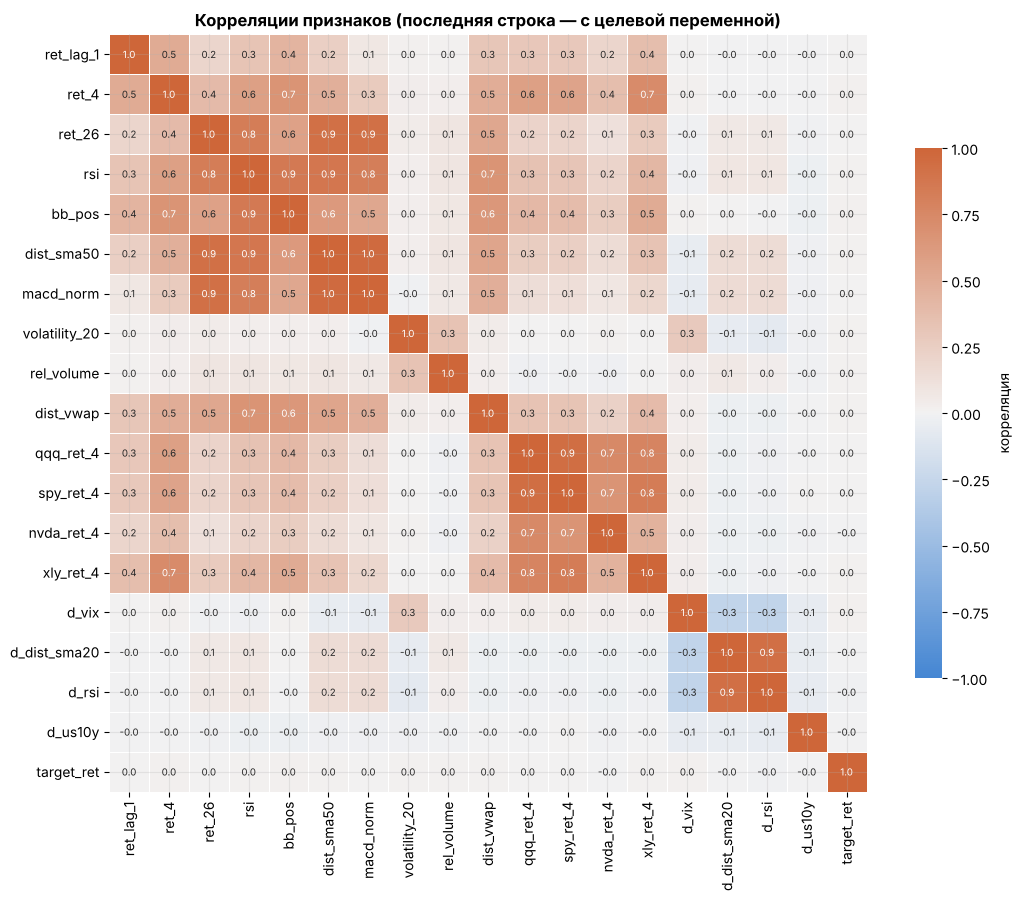

In [19]:
HEATMAP_FEATURES = ['ret_lag_1', 'ret_4', 'ret_26', 'rsi', 'bb_pos', 'dist_sma50', 'macd_norm',
                    'volatility_20', 'rel_volume', 'dist_vwap',
                    'qqq_ret_4', 'spy_ret_4', 'nvda_ret_4', 'xly_ret_4',
                    'd_vix', 'd_dist_sma20', 'd_rsi', 'd_us10y', 'target_ret']

cm = df[HEATMAP_FEATURES].corr()
cmap = sns.diverging_palette(250, 25, s=80, l=55, center='light', as_cmap=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, cmap=cmap, vmin=-1, vmax=1, center=0, square=True,
            annot=True, fmt='.1f', annot_kws={'size': 7}, linewidths=0.5, linecolor='white',
            cbar_kws={'shrink': 0.7, 'label': 'корреляция'}, ax=ax)
ax.set_title('Корреляции признаков (последняя строка — с целевой переменной)')
plt.tight_layout(); plt.show()

**Выводы по графику:** _впишите сами._ Подсказки:
1. Найдите блоки сильно связанных признаков. Совпадают ли они с парами из раздела A3?
2. Посмотрите на последнюю строку `target_ret`. Насколько сильно признаки связаны с будущим?

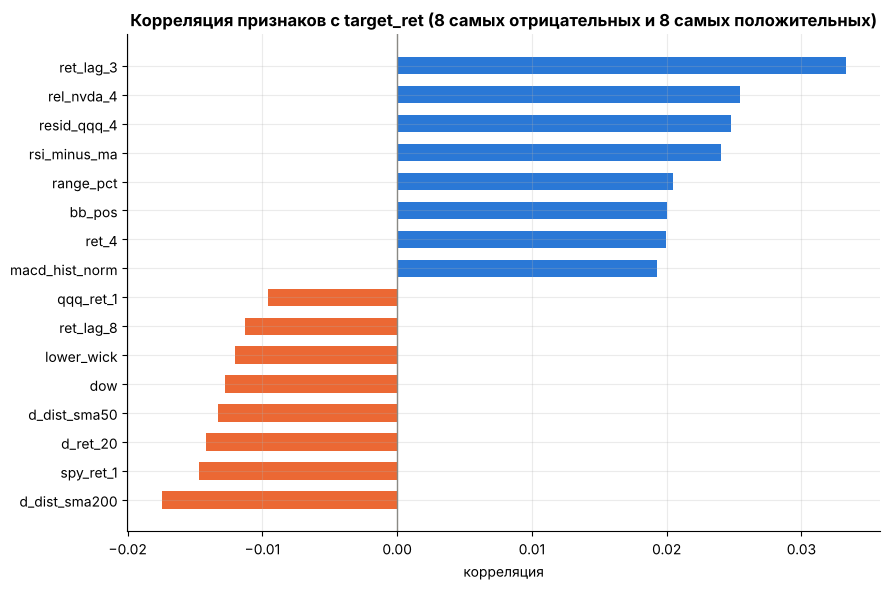

In [20]:
# Та же последняя строка крупно: связь каждого признака с будущей доходностью
target_corr = df[FEATURES].corrwith(df['target_ret']).sort_values()
top = pd.concat([target_corr.head(8), target_corr.tail(8)])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=[ORANGE if v < 0 else BLUE for v in top.values], height=0.6)
ax.axvline(0, color=GRAY, lw=1)
ax.set_title('Корреляция признаков с target_ret (8 самых отрицательных и 8 самых положительных)')
ax.set_xlabel('корреляция')
plt.tight_layout(); plt.show()

Корреляции не больше 0,03 по модулю — это **нормально для биржи**. Если бы какой-то признак давал
корреляцию 0,3 с будущей ценой, этим давно бы пользовались все. Модели придётся искать слабые
и нелинейные закономерности, поэтому честная проверка на test особенно важна.

## B6. Диаграмма рассеяния: TSLA против рынка (QQQ)

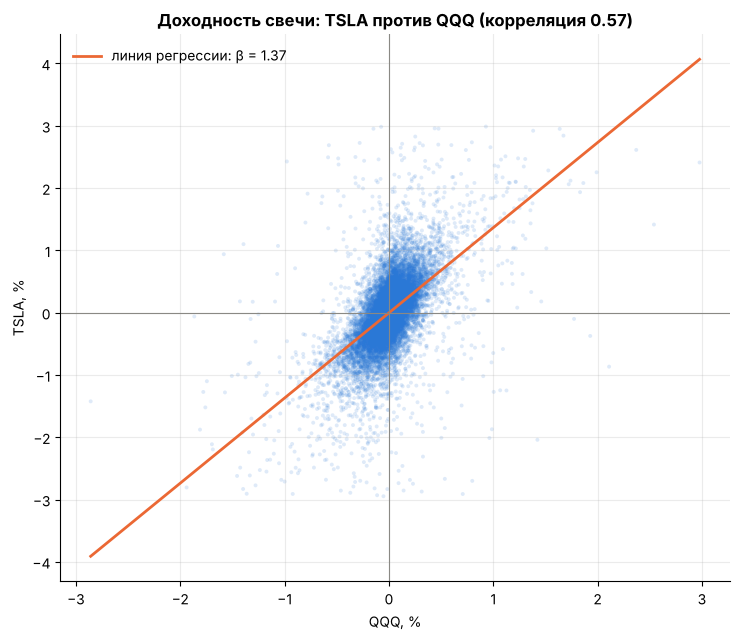

In [21]:
sample = df[['qqq_ret_1', 'ret_lag_1']].mul(100)
sample = sample[(sample.abs() < 3).all(axis=1)]          # для читаемости обрезаем экстремальные точки
slope, intercept, r_val, _, _ = stats.linregress(sample['qqq_ret_1'], sample['ret_lag_1'])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(sample['qqq_ret_1'], sample['ret_lag_1'], s=8, alpha=0.15, color=BLUE, edgecolors='none')
xs = np.linspace(sample['qqq_ret_1'].min(), sample['qqq_ret_1'].max(), 50)
ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2, label=f'линия регрессии: β = {slope:.2f}')
ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(0, color=GRAY, lw=0.8)
ax.set_title(f'Доходность свечи: TSLA против QQQ (корреляция {r_val:.2f})')
ax.set_xlabel('QQQ, %')
ax.set_ylabel('TSLA, %')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

**Выводы по графику:** _впишите сами._ Подсказка: что значит β больше 1? Если Nasdaq за 15 минут
вырос на 0,5%, на сколько в среднем меняется TSLA? Почему поэтому признаки рынка (QQQ, SPY) полезны?

---
# Часть C. Создание признаков (урок 2)

Здесь работаете вы. Каждое задание — ячейка с `# TODO`, а за ней ячейка-проверка.
Пока задание не сделано, проверка просто сообщит об этом, и ноутбук не сломается.

**Правило всех признаков на бирже:** признак в строке со временем *t* может использовать только
то, что известно **к закрытию свечи *t***. Никаких `shift(-1)` и данных из будущего.

## ✅ Задание C1. Месяц и квартал

Как в уроке с датами звонков: извлеките из `datetime` новые признаки.
- `month` — номер месяца (1–12);
- `quarter` — номер квартала (1–4).

Подсказка: у столбца с датой есть атрибут `.dt`, а у него — `.month` и `.quarter`.

In [22]:
# TODO: создайте признаки month и quarter
df['month'] = None     # ← замените None
df['quarter'] = None   # ← замените None

In [23]:
def check_c1():
    if df['month'].isna().all():
        return 'Задание C1 ещё не сделано'
    assert set(df['month'].unique()) <= set(range(1, 13)), 'month должен быть от 1 до 12'
    assert set(df['quarter'].unique()) <= {1, 2, 3, 4}, 'quarter должен быть от 1 до 4'
    return f"C1 готово ✅  месяцы: {sorted(int(m) for m in df['month'].unique())}"
check_c1()

'Задание C1 ещё не сделано'

## ✅ Задание C2. Начало и конец сессии

График B3 показал, что первые и последние свечи дня особенные. Создайте два бинарных признака:
- `is_first_hour` — 1, если свеча в первом часе торгов (09:30–10:15 включительно), иначе 0;
- `is_last_hour` — 1, если свеча в последнем часе (15:00–15:30), иначе 0.
  Свечи 15:45 в датасете нет: у неё нет следующей свечи в тот же день, и её убрали при сборке.

Подсказка: удобно использовать готовый признак `bar_of_day` (0 — свеча 09:30, 24 — свеча 15:30)
и превратить условие в число через `.astype(int)`.

In [24]:
# TODO: создайте признаки is_first_hour и is_last_hour
df['is_first_hour'] = None   # ← замените None
df['is_last_hour'] = None    # ← замените None

In [25]:
def check_c2():
    if df['is_first_hour'].isna().all():
        return 'Задание C2 ещё не сделано'
    first = df.loc[df['is_first_hour'] == 1, 'datetime'].dt.strftime('%H:%M').unique()
    last = df.loc[df['is_last_hour'] == 1, 'datetime'].dt.strftime('%H:%M').unique()
    assert set(first) == {'09:30', '09:45', '10:00', '10:15'}, f'В первом часе оказались: {sorted(first)}'
    assert set(last) == {'15:00', '15:15', '15:30'}, f'В последнем часе оказались: {sorted(last)}'
    return 'C2 готово ✅'
check_c2()

'Задание C2 ещё не сделано'

## ✅ Задание C3. Профильный внешний источник: даты квартальных отчётов Tesla

В уроке это называлось **профильной внешней информацией** — данными, важными именно для этой задачи.
Для TSLA сильнейшие движения случаются вокруг квартальных отчётов (earnings).

**Шаги:**
1. Найдите даты отчётов Tesla с сентября 2023 по октябрь 2026 на сайте для инвесторов
   (ir.tesla.com) или в любом финансовом календаре. Tesla обычно отчитывается после закрытия рынка,
   поэтому реакция цены приходится на **следующий** торговый день.
2. Впишите даты в список `EARNINGS_DATES` (формат `'ГГГГ-ММ-ДД'`, дата публикации отчёта).
3. Создайте признак `days_to_earnings` — сколько календарных дней осталось до ближайшего **будущего**
   отчёта. Это не утечка: даты отчётов компания объявляет заранее.
4. Создайте признак `is_post_earnings` — 1 в первый торговый день после отчёта.

Подсказка для п. 3: `pd.merge_asof(..., direction='forward')` находит для каждой даты ближайшую следующую.

In [26]:
# TODO: впишите даты отчётов (дата публикации, после закрытия рынка)
EARNINGS_DATES = [
    # '2023-10-18',
    # ...
]

earnings = pd.DataFrame({'earn_date': pd.to_datetime(EARNINGS_DATES)}).sort_values('earn_date')

# TODO: days_to_earnings — дней от date до ближайшего отчёта в будущем (включая сегодняшний)
df['days_to_earnings'] = None

# TODO: is_post_earnings — 1 в первый торговый день ПОСЛЕ даты отчёта
df['is_post_earnings'] = None

In [27]:
def check_c3():
    if not EARNINGS_DATES or df['days_to_earnings'].isna().all():
        return 'Задание C3 ещё не сделано'
    assert len(EARNINGS_DATES) >= 12, 'За 3 года должно быть не меньше 12 отчётов (по 4 в год)'
    assert (df['days_to_earnings'].dropna() >= 0).all(), 'days_to_earnings не может быть отрицательным'
    post_days = df.loc[df['is_post_earnings'] == 1, 'date'].nunique()
    return f'C3 готово ✅  дней после отчёта: {post_days}'
check_c3()

'Задание C3 ещё не сделано'

In [28]:
# Когда C3 сделано: правда ли, что в день после отчёта TSLA двигается сильнее?
if 'is_post_earnings' in df and not df['is_post_earnings'].isna().all():
    tmp = df.assign(abs_ret=df['ret_lag_1'].abs() * 100)
    print(tmp.groupby('is_post_earnings')['abs_ret'].mean().round(3).rename('средний |ret|, %'))

## ✅ Задание C4. Свой признак

Придумайте один признак сами. Несколько идей, если нужен старт:
- накопленная доходность QQQ за последние 3 свечи (`rolling(3).sum()` по `qqq_ret_1`);
- разница между RSI на 15 минутах и дневным RSI (`rsi - d_rsi`);
- обгоняет ли TSLA сегодня NVDA (`ret_from_open - nvda_ret_from_open`).

Не забудьте правило: только прошлое и настоящее, никакого будущего.

In [29]:
# TODO: ваш признак
MY_FEATURE = 'my_feature'      # ← придумайте понятное имя
df[MY_FEATURE] = None          # ← формула

In [30]:
def check_c4():
    if df[MY_FEATURE].isna().all():
        return 'Задание C4 ещё не сделано'
    c = df[MY_FEATURE].astype(float).corr(df['target_ret'])
    return f'C4 готово ✅  пропусков: {df[MY_FEATURE].isna().mean():.1%}, корреляция с target_ret: {c:.4f}'
check_c4()

'Задание C4 ещё не сделано'

## Сохранение

Когда задания сделаны, сохраните обновлённый датасет — на нём будем обучать модели.

In [31]:
NEW = ['month', 'quarter', 'is_first_hour', 'is_last_hour',
       'days_to_earnings', 'is_post_earnings', MY_FEATURE]
done = [c for c in NEW if c in df and not df[c].isna().all()]
print('Готовые новые признаки:', done)

if done:
    df.to_csv('tsla_15m_dataset_v2.csv', index=False)
    print('Сохранено: tsla_15m_dataset_v2.csv')
else:
    print('Пока сохранять нечего — выполните задания части C.')

Готовые новые признаки: []
Пока сохранять нечего — выполните задания части C.


---
# Итоги

Заполните своими словами — это пригодится при защите проекта:

1. **Очистка:** какие методы урока 6 подошли к биржевым данным, а какие нет и почему?
2. **Визуализация:** три главных вывода из графиков B1–B6.
3. **Признаки:** какой из новых признаков кажется самым полезным и почему?